In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate project root
root = Path.cwd()
if not (root / "data").exists():
    root = root.parent

# Load our labeled dataset
df = pd.read_csv(root / "data/processed/train_FD001_labeled.csv")

print("Dataset shape:", df.shape)
print("Total engines:", df["engine_id"].nunique())

display(df.head())


Dataset shape: (20631, 27)
Total engines: 100


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [2]:

sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

# Calculate sensor statistics
sensor_stats = pd.DataFrame({
    "unique_values": df[sensor_cols].nunique(),
    "std": df[sensor_cols].std(),
    "min": df[sensor_cols].min(),
    "max": df[sensor_cols].max()
})

# Sensors with only one unique value
constant_sensors = sensor_stats[
    sensor_stats["unique_values"] == 1
].index.tolist()

print("=== CONSTANT SENSORS ===")
print(constant_sensors)

print("\n=== SENSOR STATISTICS ===")
display(sensor_stats.round(5))


=== CONSTANT SENSORS ===
['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

=== SENSOR STATISTICS ===


,unique_values,std,min,max
sensor_1,1,0.00000,518.6700,518.6700
sensor_2,310,0.50005,641.2100,644.5300
sensor_3,3012,6.13115,1571.0400,1616.9100
sensor_4,4051,9.00060,1382.2500,1441.4900
sensor_5,1,0.00000,14.6200,14.6200
sensor_6,2,0.00139,21.6000,21.6100
sensor_7,513,0.88509,549.8500,556.0600
sensor_8,53,0.07099,2387.9000,2388.5600
sensor_9,6403,22.08288,9021.7300,9244.5900
sensor_10,1,0.00000,1.3000,1.3000


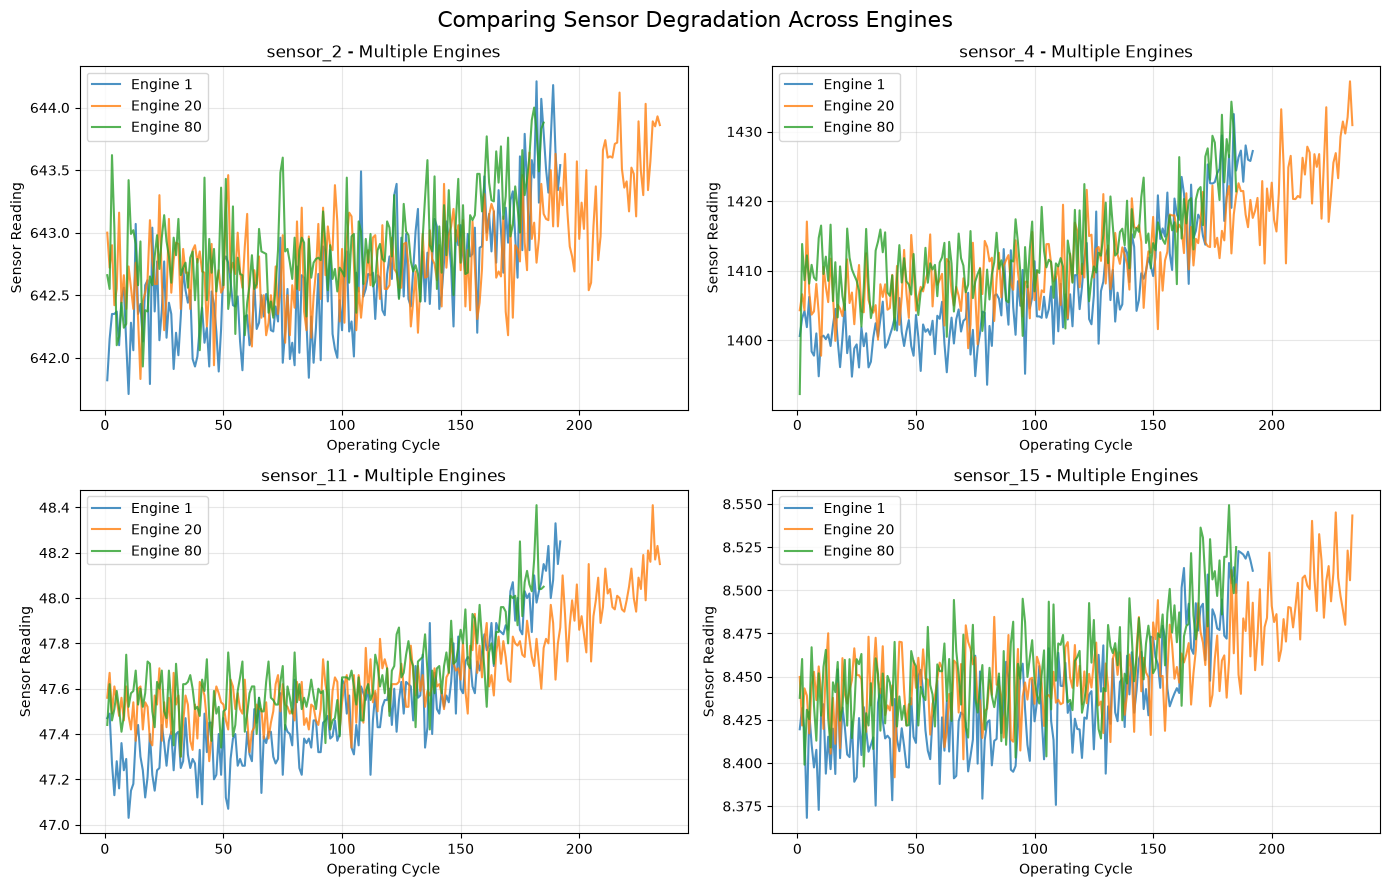

In [5]:

engine_ids = [1, 20, 80]
selected_sensors = [
    "sensor_2",
    "sensor_4",
    "sensor_11",
    "sensor_15"
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, sensor in zip(axes.flat, selected_sensors):
    for engine_id in engine_ids:
        engine = df[df["engine_id"] == engine_id]

        ax.plot(
            engine["cycle"],
            engine[sensor],
            label=f"Engine {engine_id}",
            alpha=0.8
        )

    ax.set_title(f"{sensor} - Multiple Engines")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel("Sensor Reading")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle(
    "Comparing Sensor Degradation Across Engines",
    fontsize=16
)
plt.tight_layout()
plt.show()


In [7]:

from sklearn.model_selection import train_test_split

# Get all unique engine IDs
engine_ids = sorted(df["engine_id"].unique())

# Split engines: 80% training, 20% validation
train_ids, val_ids = train_test_split(
    engine_ids,
    test_size=0.20,
    random_state=42
)

# Separate complete engine histories
train_df = df[df["engine_id"].isin(train_ids)].copy()
val_df = df[df["engine_id"].isin(val_ids)].copy()

# Verify no engine appears in both sets
overlap = set(train_ids) & set(val_ids)
assert len(overlap) == 0

# Verify all records are preserved
assert len(train_df) + len(val_df) == len(df)

print("=== TRAINING DATA ===")
print("Engines:", train_df["engine_id"].nunique())
print("Records:", len(train_df))

print("\n=== VALIDATION DATA ===")
print("Engines:", val_df["engine_id"].nunique())
print("Records:", len(val_df))

print("\n=== DATA LEAKAGE CHECK ===")
print("Overlapping engine IDs:", len(overlap))
print("No engine overlap:", len(overlap) == 0)

# Save both datasets
processed_dir = root / "data/processed"

train_df.to_csv(processed_dir / "train_split.csv", index=False)
val_df.to_csv(processed_dir / "val_split.csv", index=False)

print("\nTraining and validation datasets saved!")


=== TRAINING DATA ===
Engines: 80
Records: 16561

=== VALIDATION DATA ===
Engines: 20
Records: 4070

=== DATA LEAKAGE CHECK ===
Overlapping engine IDs: 0
No engine overlap: True

Training and validation datasets saved!
